# A knowledge graph guardrail for an AI agent, with Amazon Neptune

AnyCompany's procurement team uses an AI agent to draft purchase orders and reply to supplier
offers. The agent runs on Amazon Bedrock AgentCore Runtime. It calls the right tools, its answers
read well, and its dashboards are green.

Last week, someone sent it this request:

> *Can you put together a PO for 40 units of Server Hardware from AnyCompany Components for the
> Ashburn build-out (US-East)? They're one of our preferred vendors and Sarah in sourcing already
> gave the nod, so this should be quick.*

The agent drafted the PO. Every check it could see had passed, because AnyCompany Components is
active, gold-approved for server hardware, and licensed for US-East. A day later, compliance reversed
the order with four findings, none of which were in the request.

- **Sanctions.** Two companies controlled by a sanctioned firm together own 55% of the
  supplier's parent, three ownership levels up. Under the 50 Percent Rule of OFAC, the U.S.
  Treasury's sanctions office, that blocks the parent, and so the supplier, although neither
  is on any list.
- **Forced labour.** Three tiers down its supply chain, a maker is on the Entity List of the
  Uyghur Forced Labor Prevention Act (UFLPA), a U.S. law, so its goods are barred from import into
  the United States.
- **Certification.** The US-East build-out is for a U.S. federal customer, and its contract requires
  suppliers to meet NIST SP 800-171, the U.S. standard for protecting controlled unclassified
  information. The supplier's attestation lapsed in March 2024.
- **Stock.** The supplier has 25 units in stock, and the order is for 40.

The model didn't make a mistake. It acted on what it was told, and nothing stood between its
decision and the action. The two findings that matter most aren't facts about the supplier at all.
They're relationships several hops away, between owners of owners and suppliers of suppliers, at a
depth nobody knows in advance, and no prompt can make the model find them.

AnyCompany and every supplier in its registry are synthetic, but the rules are real. The sanctions
rule is OFAC's, the forced-labor rule is the UFLPA's, and NIST SP 800-171 is a real requirement in
U.S. federal contracts. Steps 2 and 3 say where each input comes from in production, and the FAQ in
the workshop guide explains why the registry is synthetic.

## What we'll build

In this workshop, we'll build a **guardrail** for this agent. It's a hook that runs before every
action, in code the model has no say over, and checks the action against rules that walk a knowledge
graph in Amazon Neptune.

We'll put the guard in front of the agent first, before it has any rules, and send it the order.
Each step then teaches the guard more, and we send **the same order** again to see what the agent
does with it.

| Step | You add to the guard | What the agent does with the order |
|---|---|---|
| 1 · Adding a hook before every tool call | a hook before every tool call (you write it) | still drafts it: the guard has no rules yet |
| 2 · Computing OFAC's 50 percent rule | OFAC's 50% rule (you write it), computed over the ownership graph | blocked, for sanctions |
| 3 · Checking every rule in one report | forced labour, certification, stock | blocked, with all four reasons |
| 4 · Testing and deploying the guardrail | nothing: you test it, and deploy it | blocked even when called directly or pressured; blocked and redirected in production |

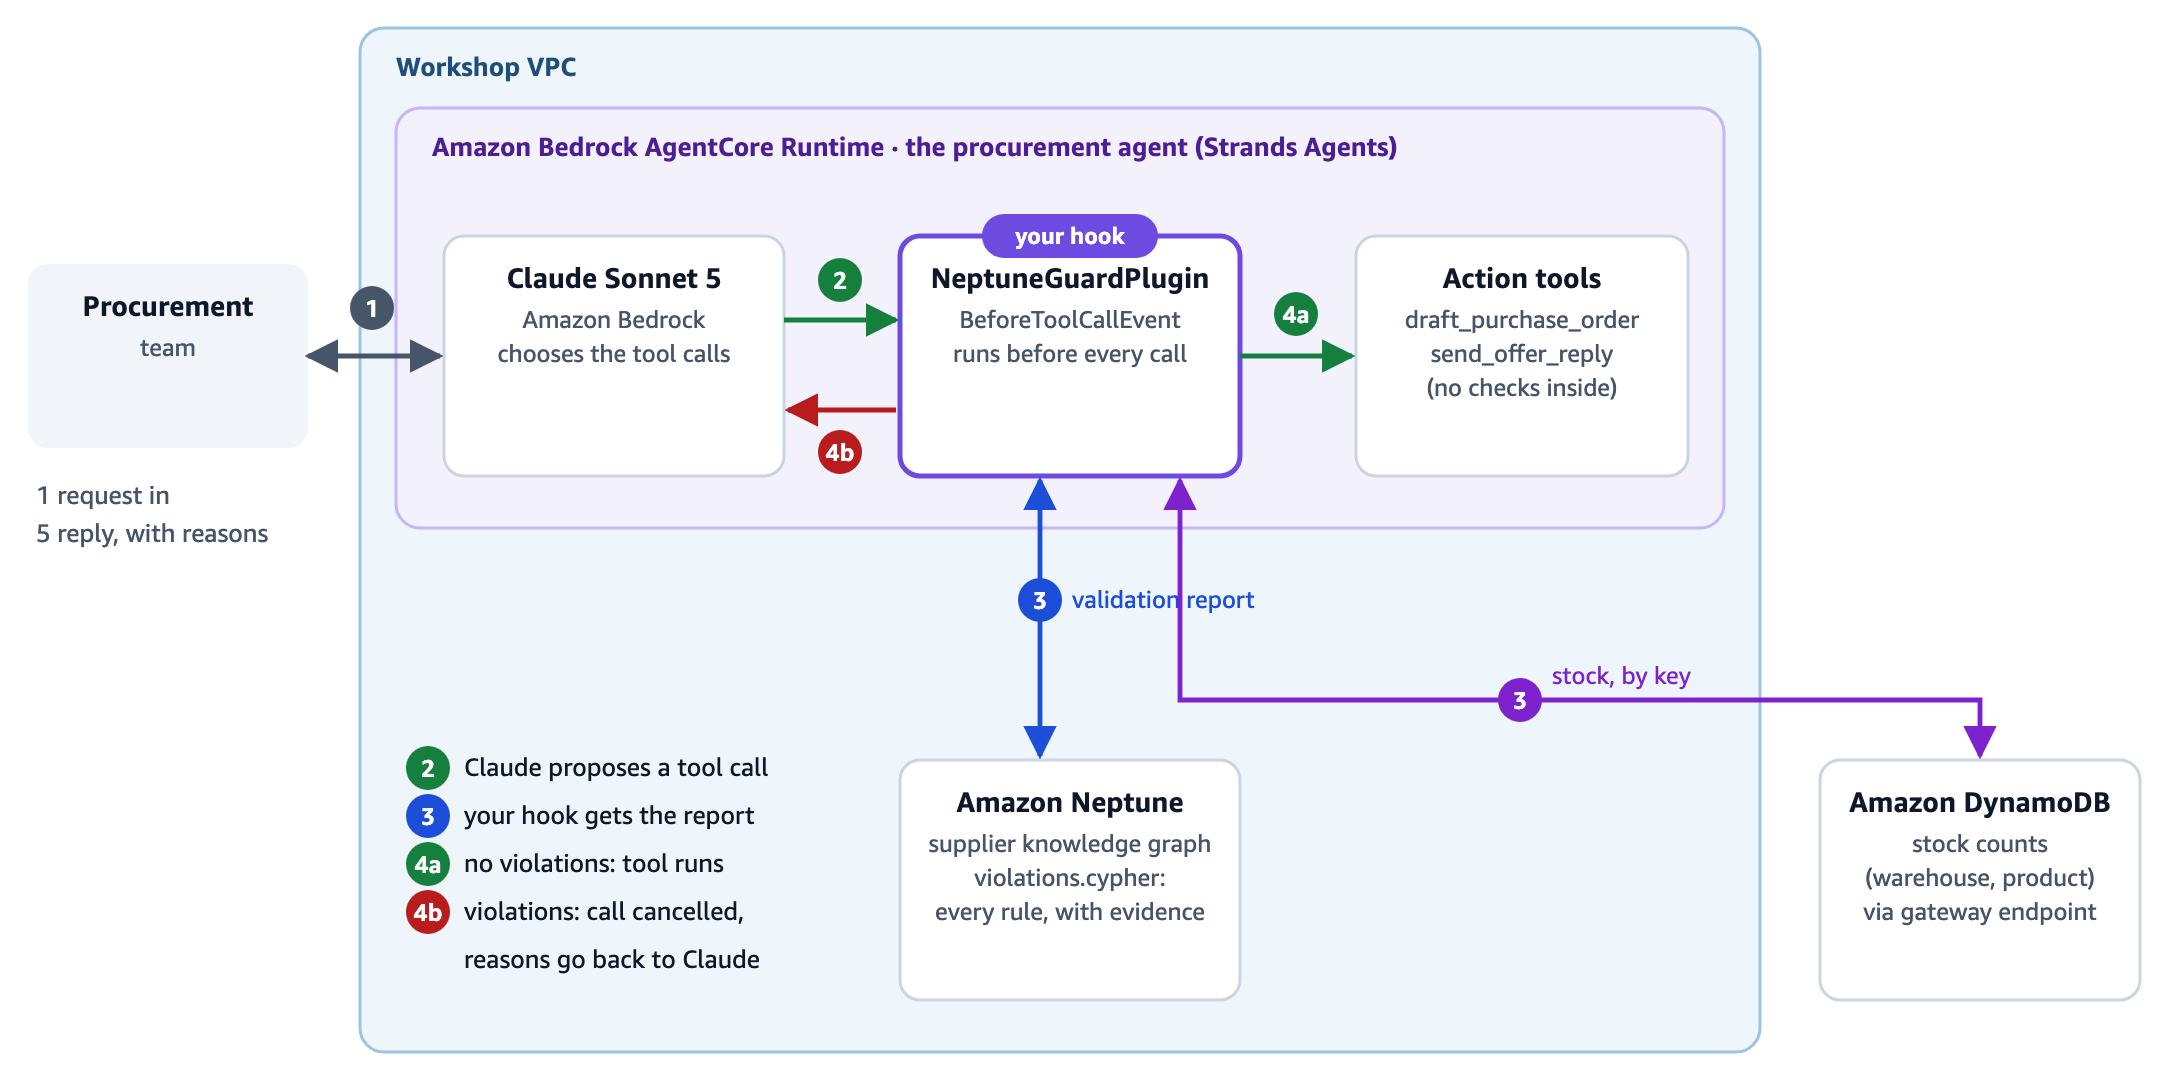

**How to run it.** The session is notebook 1, which is the folder `1 - Build the guardrail`. It
holds four notebooks, one per step, numbered 1.1 to 1.4 in the order you open them, and this is 1.1.
Select a cell and press **Shift+Enter**, and run the cells in order. Each notebook starts with a
Connect cell, and if the kernel restarts, run that cell again and carry on. The workshop guide has a
page for each notebook with more background.

## Start · The agent today

Before we build anything, let's see the problem for ourselves. We'll connect to the workshop stack,
and then send the order from the top of this notebook to the agent as it runs today, with no guard.

**Cell 0.1 · Connect.** Every notebook starts here. The cell reads the stack's resources (the
Neptune endpoint, the DynamoDB stock table and the deployed agents) from `workshop_config.txt`. It
also checks that the instance loaded the graph and the stock table when it started, and waits if a
load is still running.

The cell prints three green lines, for the graph (about 50,000 suppliers), the stock table, and
*Setup complete*, with the order we'll follow for the whole session.

In [ ]:
# Cell 0.1 · Connect
import sys, os; sys.path.insert(0, os.path.join(os.path.expanduser("~"), "SageMaker", "workshop", "helpers"))
from session import connect
connect(globals())

> **What you should see.** The last line is *Setup complete*, followed by `ORDER`, which is 40 x Server Hardware from
> AnyCompany Components to US-East. If the cell is waiting on a load, let it finish. After a kernel
> restart, run this cell again.
>
> **Why it matters.** `connect` puts the session's names in the notebook (`ORDER`, `HEADLINE`, `build_agent`,
> `NeptuneGuardPlugin`, `guard_rules` and others), so the cells that follow can show their real code
> rather than call hidden helpers.

**Cell 0.2 · The unguarded agent.** First, the problem. This is the agent as it runs today, deployed
on Amazon Bedrock AgentCore Runtime. It has Claude, a system prompt, and two action tools,
`draft_purchase_order` and `send_offer_reply`. The tools are clean actions with no checks inside, and
nothing sits between them and the model.

The cell sends the request from the top of this notebook, word for word, and shows each tool call the
agent made, followed by its reply. `[ok]` means the tool ran.

**What runs, and where.**

- `invoke_deployed_agent(...)`, in [`helpers/deploy_agent.py`](../helpers/deploy_agent.py), calls the AgentCore Runtime
  data plane (`invoke_agent_runtime`) with the request as its payload. The agent answers inside
  AgentCore, and returns its reply and a trace with one entry per tool call, which the cell prints.
- The agent was deployed by the workshop's CloudFormation stack before you arrived. It's the same
  Strands agent that `build_agent()` builds in [`helpers/guardrail.py`](../helpers/guardrail.py), with no guard plugin.
- `show_request` and `show_reply`, in [`helpers/ui.py`](../helpers/ui.py), only display.

*Predict: AnyCompany Components is active, gold-approved for Server Hardware and licensed for
US-East. Will the agent draft the PO?*

In [ ]:
# Cell 0.2 · The unguarded agent
show_request(HEADLINE)
reply = invoke_deployed_agent(os.environ["UNGUARDED_AGENT_RUNTIME_ARN"], HEADLINE, show_calls=True)
show_reply(reply, "Unguarded agent")

> **What you should see.** The trace shows `[ok] draft_purchase_order(...)` and a `PO-DRAFT-...` number. The agent did what it
> was asked, and every fact it was given was true.
>
> **Why it matters.** Nothing in the agent's loop could find the four problems, because they're relationships several hops
> away in the supplier registry. A better prompt wouldn't help either, because the model can't check
> what it can't see. The next cell shows where the four problems are.

<div class="alert alert-block alert-warning"><b>Stuck?</b> If Cell 0.1 says the instance is still loading the graph, let it wait, because the load finishes
on its own. If Cell 0.2 fails with a missing <code>UNGUARDED_AGENT_RUNTIME_ARN</code>, ask a facilitator, and
carry on with Cell 0.3, since nothing later depends on it.</div>

**Cell 0.3 · What the agent couldn't see.** The agent checked three facts, and each one sits next to
the supplier in the graph. The supplier is active, it has an `APPROVED_FOR` edge to Server Hardware,
and it has an `OPERATES_IN` edge to US-East. The four findings are in the same graph, further out.

The query is written the way a production query should be.

- **It finds its starting points once.** The first `MATCH` looks up the supplier, the product and the
  region on the order, and `CALL { ... }` runs every walk from those three vertices. `WITH s` hands
  each branch only what it needs, and `UNION` joins the paths the branches return.
- **It takes parameters.** `$supplier_name`, `$product_name` and `$region_name` come from `params`,
  which Cell 0.1 set to the order, and `-qp params` passes them in. Neptune caches one plan for the
  query and reuses it for any order, and no value is ever pasted into the query text.
- **Its walks are unbounded, because we know this dataset.** `*1..` follows an edge as many times as
  the chain goes. The deepest chain in this registry is eight ownership hops, and every walk starts
  from one supplier, so the walks stay small. In production, an unbounded walk's cost depends on the
  data, and a densely connected stretch of graph can multiply the paths it explores. Consider setting
  an upper bound, such as `*1..12`, chosen from the depth of your own data, and decide what the guard
  does when a chain reaches it (the FAQ covers this).

The branches make one walk for each finding.

- **What the agent checked** is one hop each, to the product and the region on the order.
- **F1 · Sanctions** goes up `OWNED_BY`, any number of hops, to a company on OFAC's list. Each
  `OWNED_BY` edge is labelled with its stake.
- **F2 · Forced labor** goes down `SOURCES_FROM`, any number of hops, to a company on the UFLPA
  Entity List.
- **F3 · Certification** goes across to the certification that US-East requires. The supplier's
  `HOLDS_CERT` edge is labelled with its status.
- **F4 · Stock** goes to the supplier's warehouses, where they are, and what they carry. The unit
  counts change all day, so they live in DynamoDB, and we read them in Step 3.

`%%oc` runs the query in Neptune. Choose the **Graph** tab to see the result, and drag a vertex to
untangle it. Vertices are coloured by label, and you can click one to see its properties.

**Two kinds of graph picture.** This one is native. graph-notebook's Graph tab draws whatever paths
Neptune returns, and every `%%oc` cell in the workshop has one. Later cells also draw diagrams of
their results, such as a check's verdicts or a stock count from DynamoDB, which Neptune doesn't hold.
Those diagrams are drawn from the query's rows by `ui.py`, the workshop's display helper, and each one
says so underneath, along with where to find Neptune's own view of the same data.

*Predict: the agent's checks were one hop out. How far out is the furthest finding?*

In [ ]:
%%oc -qp params -d name -de {"OWNED_BY":"share_pct","HOLDS_CERT":"cert_status"} -l 40 -rel 40
// Cell 0.3 · What the agent couldn't see
// Find the order's three vertices once; every walk below starts from them
MATCH (s:Supplier {name: $supplier_name}), (prod:Product {name: $product_name}),
      (r:Region {name: $region_name})
CALL {
  // What the agent checked: one hop each, to the product and the region
  WITH s, prod
  MATCH p = (s)-[:APPROVED_FOR]->(prod)
  RETURN p
  UNION
  WITH s, r
  MATCH p = (s)-[:OPERATES_IN]->(r)
  RETURN p
  UNION
  // F1 sanctions: up its owners, any number of hops, to a company on OFAC's list
  WITH s
  MATCH p = (s)-[:OWNED_BY*1..]->(:Company)-[:SANCTIONED_BY]->(:SanctionsList)
  RETURN p
  UNION
  // F2 forced labor: down its supply chain, any number of hops, to a company on the UFLPA list
  WITH s
  MATCH p = (s)-[:SOURCES_FROM*1..]->(:Company)-[:ON_LIST]->(:RestrictedList)
  RETURN p
  UNION
  // F3 certification: what the region requires, and the supplier's record of it
  WITH s, r
  MATCH p = (s)-[:HOLDS_CERT]->(:Certification)<-[:REQUIRES_CERT]-(r)
  RETURN p
  UNION
  // F4 stock: the warehouses that carry the product (the counts live in DynamoDB) ...
  WITH s, prod
  MATCH p = (s)-[:HAS_WAREHOUSE]->(:Warehouse)-[:STOCKS]->(prod)
  RETURN p
  UNION
  // ... and where those warehouses are
  WITH s, prod
  MATCH (s)-[:HAS_WAREHOUSE]->(w:Warehouse)-[:STOCKS]->(prod)
  MATCH p = (w)-[:LOCATED_IN]->(:Region)
  RETURN p
}
RETURN p

> **What you should see.** The graph has 16 vertices around AnyCompany Components. Server Hardware and US-East are one hop away,
> which is as far as the agent looked. OFAC's list is four hops up, through two ownership routes that
> meet at AnyCompany Components Holdings BV, at 30% and 25%. The UFLPA list is four hops down, past three
> tiers of suppliers. The `HOLDS_CERT` edge to NIST-800-171 says `expired`, and US-East has a
> `REQUIRES_CERT` edge to the same vertex. The only warehouse is in Amsterdam, in EU-West.
>
> **Why it matters.** Every fact the agent needed was already in the registry. The agent saw the facts next to the
> supplier, and the findings were two to four hops further out, at depths that differ from one supplier
> to the next. A graph stores those relationships as edges, so a single query can follow them however
> deep they turn out to be. The guard will ask Neptune these questions before every action, and in Step 1 we put the
> guard in place.

## Step 1 · Adding a hook before every tool call

The agent's tools run the moment the model calls them. In this step, we'll put a guard between the
model's decision and the tool, before the guard knows a single rule, and send the same order through
it. Doing it in this order matters. Once every consequential action goes through one place, each rule
we add later applies to all of them, with no change to the agent.

The guard is a **hook**. Strands Agents, the SDK the agent is built on, fires a `BeforeToolCallEvent`
before every tool call and runs every hook registered for it. The event carries the call in
`event.tool_use`, which holds the tool's `name` and its `input`. It also has one field that matters
here. If a hook sets `event.cancel_tool` to a string, **the tool never runs**, and the string becomes
the tool's result, which the model reads as if the tool had answered. The model can't skip the hook,
because running it isn't the model's choice.

A hook lives on a plugin. The plugin below is in `neptune_guard.py`, and its `before_tool` method is
the part you write.

```python
class NeptuneGuardPlugin(Plugin):
    name = "neptune-guard"

    def __init__(self, rules=None):
        super().__init__()
        self.rules = rules or importlib.import_module("guard_rules")

    @hook
    def before_tool(self, event: BeforeToolCallEvent) -> None:
        ...   # ✏️ Cell 1.1
```

`self.rules` is `guard_rules.py`, which holds the three functions the hook calls. They're given for
now, and Go deeper has you write two of them.

| Function | What it answers |
|---|---|
| `should_check(tool, args)` | does this call commit AnyCompany to something? Every PO does. |
| `run_report(args)` | the validation report for this supplier, product and region: a list of rows, one per broken rule. It **raises** if the report can't run (Neptune unreachable, a bad query, a missing argument). |
| `block_message(supplier, product, region, report)` | `None` if nothing in the report blocks; otherwise the text the model should read, starting `BLOCKED`. |

**Cell 1.1 · ✏️ The hook.** Write `before_tool`. The first lines are given. They read the call, and
let it run if `should_check` says it doesn't need checking. The rest is yours, and the three ✏️
comments in the cell say what it has to do.

These are the pieces you'll need.

| Piece | What it does |
|---|---|
| `self.rules.run_report(args)` | returns the report for the call, or **raises** if it can't be produced |
| `self.rules.block_message(supplier, product, region, report)` | returns the text the model should read, or `None` if nothing blocks |
| `args["supplier_name"]`, `args["product_name"]`, `args["region_name"]` | the order the call is about |
| `event.cancel_tool` | set it to a string and the tool doesn't run; the string becomes the tool's result |

Remember that the guard has to **fail closed**. If the report can't be produced for any reason, the
action mustn't happen, and the message the model reads should start with `BLOCKED`.

Run the cell. `save_hook` saves your method into `neptune_guard.py` and loads it. Saving isn't the
same as passing, so if a ✏️ step is still missing, the cell says so in red and names what's missing.
Cell 1.2 is the check.

In [ ]:
# Cell 1.1 · ✏️ The hook
@hook
def before_tool(self, event: BeforeToolCallEvent) -> None:
    tool = event.tool_use.get("name", "")
    args = event.tool_use.get("input") or {}
    if not self.rules.should_check(tool, args):
        return                     # not a consequential call: let it run
    # ✏️ 1. Get the report. If that fails for any reason, block the call and stop (fail closed).
    # ✏️ 2. Find out what the model should be told about this order.
    # ✏️ 3. If there's something to tell it, stop the tool and pass the message on.

save_hook(before_tool)

<details>
<summary>🔑 Reveal the Cell 1.1 solution</summary>

Replace the cell above with this, and run it again.

```python
@hook
def before_tool(self, event: BeforeToolCallEvent) -> None:
    tool = event.tool_use.get("name", "")
    args = event.tool_use.get("input") or {}
    if not self.rules.should_check(tool, args):
        return                     # not a consequential call: let it run
    try:
        report = self.rules.run_report(args)
    except Exception as e:
        # Fail closed: an action that can't be proven valid doesn't happen.
        event.cancel_tool = (f"BLOCKED: could not validate this action against Neptune "
                             f"({type(e).__name__}: {e}). No action was taken.")
        return
    message = self.rules.block_message(args.get("supplier_name"), args.get("product_name"),
                                       args.get("region_name"), report)
    if message:
        event.cancel_tool = message

save_hook(before_tool)
```

</details>

**Cell 1.2 · Check the hook.** Before the hook goes in front of the real agent, we'll test it the
way we'd test any guard, on inputs we control, with no graph and no model. `FakeRules` stands in for
`guard_rules.py`. It checks every PO, and its `run_report` returns whatever report we hand it, or
raises whatever error we hand it. The cell builds a real agent with your hook and calls the PO tool
**directly**, through `agent.tool`, the way a script would.

The first case, a report with one violation, is written out in the cell. `check_hook()` then runs it
again, along with three more cases.

- With an empty report, the PO must run.
- With a report that can't run (it raises `ConnectionError`), the PO must be blocked.
- With a call that needs no check (declining an offer), the call must run, and the report must not
  even be requested.

**What runs, and where.**

- `FakeRules` and `check_hook()` are in [`helpers/session.py`](../helpers/session.py). For each of the four cases,
  `check_hook()` builds a real agent with your hook and a `FakeRules` that returns the case's report,
  or raises its error. It calls the tool directly with `agent.tool`, with no model involved, and
  compares what happened with what should have happened.
- On a FAIL, it keeps your file as `neptune_guard.py.mine` and loads the reference answer from
  `helpers/reference/`, so the next cells still work.

*Predict: if you forgot the `try`, which case would fail, and how?*

In [ ]:
# Cell 1.2 · Check the hook
rules = FakeRules(report=[{"rule": "sanctions", "severity": "violation",
                           "message": "Blocked under the OFAC 50 Percent Rule", "evidence": [], "hops": 3}])
agent = build_agent(guard=NeptuneGuardPlugin(rules=rules))
result = agent.tool.draft_purchase_order(record_direct_tool_call=False, **PO)
show_direct_call("C · your hook, a report with a violation", result)

check_hook()   # the same, plus an empty report, a report that can't run, a call that needs no check

> **What you should see.** The cell shows a green BLOCKED line for the first case, then four PASS rows, followed by the text
> the model reads in place of a PO number. If a case fails, your version is kept as
> `neptune_guard.py.mine` and the reference is loaded, so the next cells still work.
>
> **Why it matters.** Without the `try`, a report that can't run doesn't block the PO. The exception escapes the hook, and
> what happens next is up to the framework rather than the guard. The case that matters most in
> production, when the graph is unreachable, is exactly the one a happy-path test never exercises. We
> run it against the real agent in Step 4.

<div class="alert alert-block alert-warning"><b>Stuck?</b> If the check fails, your version is kept as <code>neptune_guard.py.mine</code> and the reference is loaded, so
you can run Cell 1.3 next either way. If you're out of time, or want to skip writing the hook, run
<code>catch_up("hook")</code> in a new cell, and then run Cell 1.2 to confirm.</div>

**Cell 1.3 · Send the order through your guard.** Now we put your hook in front of the agent and
send the same request. Each line does one thing.

- `install_rules([])` means the report runs no rules yet. One check is always on, so a supplier that
  isn't in the registry is still blocked.
- `build_agent(guard=NeptuneGuardPlugin(rules=reload(guard_rules)))` builds the same model and
  action tools as the agent in Cell 0.2, plus your hook, and `recommend_alternatives` for when it's
  blocked. It runs here in the notebook, so we can watch what the hook does.
- `ask(agent, HEADLINE)` sends the original request, word for word.
- `record("Step 1", reply)` reads the agent's trace and adds the outcome to the order's scoreboard.

**What runs, and where.**

- `install_rules([...])`, in [`helpers/session.py`](../helpers/session.py), writes the rule names to
  [`your-guard/queries/installed_rules.json`](../your-guard/queries/installed_rules.json). The report reads that list as `$rules`.
- `build_agent(guard=...)`, in [`helpers/guardrail.py`](../helpers/guardrail.py), builds a Strands `Agent` with the
  Claude model on Amazon Bedrock, the two action tools, `recommend_alternatives`, and your
  `NeptuneGuardPlugin` from [`your-guard/neptune_guard.py`](../your-guard/neptune_guard.py) as a plugin.
- `ask(agent, HEADLINE)`, in [`helpers/session.py`](../helpers/session.py), sends the request and shows the trace.
  The trace comes from `trace()` in `guardrail.py`, which pairs each tool call in the conversation
  with its result, and marks a call `BLOCKED` when the hook cancelled it.
- `record(...)`, in `session.py`, finds the PO call in that trace, counts the rules named in its
  block message, and saves the line to the scoreboard (`your-guard/.scoreboard.json`).

*Predict: your hook runs before the PO tool. With no rules, what does it decide?*

In [ ]:
# Cell 1.3 · Send the order through your guard
install_rules([])

agent = build_agent(guard=NeptuneGuardPlugin(rules=reload(guard_rules)))
reply = ask(agent, HEADLINE)

record("Step 1", reply)

> **What you should see.** The trace shows `[ok] draft_purchase_order(...)` again, and the scoreboard says
> `Step 1   drafted the PO`. Your hook did run. It asked for a report and got an empty one, so
> `block_message` returned `None`, and the tool ran.
>
> **Why it matters.** The hook is in place, and every PO now goes through it, but a guard is only as good as its rules.
> From here on, the agent code doesn't change. Each step adds rules, and we run these same lines
> again.

<div class="alert alert-block alert-success"><b>In your system.</b> Put a hook on every tool that commits your business to something, before you have a single rule, so
that there's exactly one place where every rule runs. Return the reasons as the tool's result, so the
model can explain the decision and move on.</div>

**Next: open `1.2 - Computing OFAC's 50 percent rule.ipynb`**, in this folder, for Step 2 · Computing OFAC's 50 percent rule.

Your work is saved in `your-guard/`, so the next notebook picks it up when it connects.